# How much of the campaign conversion gap is *who* each campaign reached?

Exploratory work behind the memo (`docs/designs/memo-who-explains-the-gap.md`).

**Question.** Free-trial campaigns (trial start months) convert to paid at very different rates. For the best and worst campaign, how much of that gap is explained by the audience each campaign acquired (signup channel, city, age, gender, time since registration)?

**Method** (design doc, Approach A headline):
- Logistic model on the modeled Full population: converted ~ campaign + audience traits.
- Best and worst campaign picked once, on raw conversion, among campaigns with at least 2,000 trials.
- Explained by audience: give each worst-campaign trialist the traits of a randomly drawn best-campaign trialist, keep the worst campaign's own effect, and measure how much predicted conversion rises. As a share of the raw gap, that's *Z*.
- Per-trait split: Shapley values over the five traits (2^5 = 32 counterfactuals).
- Uncertainty: 200 bootstrap replicates resampling trialists within campaign; best and worst stay fixed.

**Prerequisite:** `python -m src.pipeline ingest` and `python -m src.pipeline campaign_rates` (this notebook reads `data/cache/`).

In [1]:
import json
import sys
import time
from itertools import combinations
from math import factorial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import definitions as d
from src import campaign_rates

# src.campaign_rates selects the non-interactive Agg backend for the pipeline; show plots inline here.
%matplotlib inline

CACHE = ROOT / 'data' / 'cache'
FIG = ROOT / 'docs' / 'designs' / 'figures' / 'who-explains-the-gap'
FIG.mkdir(parents=True, exist_ok=True)
TRAITS = list(campaign_rates.MIX_COLUMNS)

## 1. The population and the gap

In [2]:
trials = pd.read_parquet(CACHE / 'trials.parquet')
mix = pd.read_parquet(CACHE / 'mix.parquet')
df = trials.merge(mix, on=['msno', 'trial_start'], validate='one_to_one')
df = df.assign(converted=df['converted'].astype(int))
sizes = df.groupby('campaign').size()
modeled = sorted(sizes[sizes >= d.MIN_CAMPAIGN_TRIALS].index)
data, dropped = campaign_rates.drop_rare_levels(df[df['campaign'].isin(modeled)], d.MIN_MIX_LEVEL_TRIALS)
data = data.reset_index(drop=True)
print(f'{len(df):,} Full trials; {len(data):,} modeled in {len(modeled)} campaigns; rare-level drops: {dropped}')

raw = data.groupby('campaign')['converted'].agg(n='size', converted='sum', rate='mean')
BEST, WORST = raw['rate'].idxmax(), raw['rate'].idxmin()
GAP = raw.loc[BEST, 'rate'] - raw.loc[WORST, 'rate']
print(f'Best {BEST}: {raw.loc[BEST, "rate"]:.2%}   worst {WORST}: {raw.loc[WORST, "rate"]:.2%}   gap {GAP * 100:.2f} points')
raw.assign(rate_pct=(raw['rate'] * 100).round(2)).drop(columns='rate')

329,370 Full trials; 321,506 modeled in 7 campaigns; rare-level drops: {'registered_via': {'16': 1}, 'reg_lag_band': {'missing': 6}}
Best 2016-06: 8.01%   worst 2016-10: 3.25%   gap 4.76 points


,n,converted,rate_pct
campaign,,,
2015-06,102409,3982,3.89
2016-06,8852,709,8.01
2016-07,11248,738,6.56
2016-08,17500,784,4.48
2016-09,28167,1309,4.65
2016-10,56282,1828,3.25
2016-11,97048,3848,3.97


## 2. Who did the best and worst campaign reach?

Share of each campaign's trialists in each trait level (%), the difference, and the pooled conversion rate of that level across all modeled trials.

In [3]:
def composition(col):
    pair = data[data['campaign'].isin([BEST, WORST])]
    share = pair.groupby('campaign')[col].value_counts(normalize=True).unstack(0) * 100
    rate = data.groupby(col)['converted'].mean() * 100
    out = share[[BEST, WORST]].fillna(0).assign(diff=lambda x: x[BEST] - x[WORST], conv_rate_pct=rate)
    return out.round(1).sort_values('diff', key=abs, ascending=False)

compositions = {col: composition(col) for col in TRAITS}
for col, table in compositions.items():
    print(f'--- {col}')
    display(table)

--- registered_via


campaign,2016-06,2016-10,diff,conv_rate_pct
registered_via,,,,
4,21.7,70.5,-48.9,1.4
3,48.2,18.1,30.1,5.3
9,27.9,10.5,17.4,7.7
7,2.3,0.9,1.4,4.7


--- city


campaign,2016-06,2016-10,diff,conv_rate_pct
city,,,,
1,52.8,79.5,-26.6,1.7
5,9.3,4.2,5.1,7.4
13,7.0,2.6,4.4,13.7
other,7.0,2.9,4.1,8.1
22,5.4,2.2,3.1,8.7
4,5.8,2.8,3.0,8.0
15,4.3,1.9,2.3,9.8
6,3.4,1.6,1.9,8.2
12,1.8,0.8,1.1,7.2


--- age_band


campaign,2016-06,2016-10,diff,conv_rate_pct
age_band,,,,
unknown,48.6,75.5,-26.9,2.1
<=24,21.8,11.3,10.5,8.1
25-34,16.7,6.8,9.9,9.4
35+,12.9,6.5,6.4,4.4


--- gender


campaign,2016-06,2016-10,diff,conv_rate_pct
gender,,,,
unknown,44.5,73.9,-29.5,2.1
male,27.7,12.7,15.1,7.4
female,27.8,13.4,14.4,6.9


--- reg_lag_band


campaign,2016-06,2016-10,diff,conv_rate_pct
reg_lag_band,,,,
61-365,32.6,59.5,-26.9,1.6
366-1095,34.7,16.3,18.4,5.5
1096+,29.1,11.3,17.8,9.6
0-60,3.6,12.9,-9.3,5.0


## 3. Fit the model and decompose the gap

The model is additive on the log-odds scale, so swapping trait *c* from a donor changes a trialist's linear predictor by `beta_c[donor level] - beta_c[own level]`. Every subset counterfactual is then exact and cheap. The cell checks this against `predict()` once.

In [4]:
FORMULA = f'converted ~ C(campaign) + {campaign_rates.MIX_TERMS}'


def fit(frame, formula=FORMULA):
    res = smf.logit(formula, data=frame).fit(disp=0, maxiter=200)
    campaign_rates.require_converged(res, 'decomposition')
    return res


def level_effect(res, col, values):
    """Coefficient of each value's level; the reference level is 0."""
    prefix = f'C({col})[T.'
    eff = {k[len(prefix):-1]: v for k, v in res.params.items() if k.startswith(prefix)}
    return values.map(eff).fillna(0.0).to_numpy()


def decompose(res, frame, rng, traits=TRAITS, worst=None, best=None):
    """v(S) for every trait subset S, Shapley value per trait, and the full v.

    Each worst-campaign trialist gets one donor drawn uniformly from the best campaign; the
    worst campaign's fixed effect is kept in every counterfactual.
    """
    worst = worst or WORST
    best = best or BEST
    w_idx = frame.index[frame['campaign'] == worst]
    donors = rng.choice(frame.index[frame['campaign'] == best], size=len(w_idx), replace=True)
    eta = res.fittedvalues.loc[w_idx].to_numpy()
    delta = {
        c: level_effect(res, c, frame.loc[donors, c].reset_index(drop=True))
        - level_effect(res, c, frame.loc[w_idx, c].reset_index(drop=True))
        for c in traits
    }
    sig = lambda x: 1 / (1 + np.exp(-x))
    base = sig(eta).mean()
    value = {
        S: sig(eta + sum((delta[c] for c in S), np.zeros_like(eta))).mean() - base
        for k in range(len(traits) + 1)
        for S in combinations(traits, k)
    }
    n = len(traits)
    phi = {}
    for c in traits:
        others = [x for x in traits if x != c]
        phi[c] = sum(
            factorial(k) * factorial(n - k - 1) / factorial(n)
            * (value[tuple(x for x in traits if x in S or x == c)] - value[S])
            for k in range(n)
            for S in combinations(others, k)
        )
    return value[tuple(traits)], phi, (w_idx, donors)


t0 = time.time()
res = fit(data)
v_all, phi, (w_idx, donors) = decompose(res, data, np.random.default_rng(d.DECOMPOSITION_SEED))

# Check the additive shortcut against statsmodels' own prediction.
cf = data.loc[w_idx].copy()
cf[TRAITS] = data.loc[donors, TRAITS].to_numpy()
v_check = res.predict(cf).mean() - res.predict(data.loc[w_idx]).mean()
assert abs(v_check - v_all) < 1e-9, (v_check, v_all)
assert abs(sum(phi.values()) - v_all) < 1e-12

Z = v_all / GAP
print(f'fit + decomposition {time.time() - t0:.1f}s; pseudo R^2 {res.prsquared:.3f}')
print(f'Raw gap {GAP * 100:.2f} points; explained by audience {v_all * 100:.2f} points = {Z:.1%}; '
      f'not explained {(GAP - v_all) * 100:.2f} points')
pd.Series({c: f'{p * 100:+.2f} pts ({p / GAP:+.1%} of gap)' for c, p in phi.items()}, name='Shapley share')

fit + decomposition 4.1s; pseudo R^2 0.127
Raw gap 4.76 points; explained by audience 3.37 points = 70.8%; not explained 1.39 points


registered_via    +1.88 pts (+39.5% of gap)
city              +1.90 pts (+39.8% of gap)
age_band           +0.11 pts (+2.3% of gap)
gender            -0.62 pts (-12.9% of gap)
reg_lag_band       +0.10 pts (+2.2% of gap)
Name: Shapley share, dtype: str

## 4. Robustness

- **Monte Carlo noise:** the donor draw is random; repeat it 20 times.
- **Profile fields:** age and gender are blank for most members, and blank profiles convert at ~2%. If KKBox only collects these fields at checkout, they'd leak the outcome. Refit without them.
- **Direction:** give *best*-campaign trialists the worst campaign's audience instead (the other Oaxaca reference).

In [5]:
draws = [decompose(res, data, np.random.default_rng(s))[0] / GAP for s in range(20)]
print(f'Z over 20 donor draws: mean {np.mean(draws):.1%}, sd {np.std(draws):.2%}, '
      f'range {min(draws):.1%} to {max(draws):.1%}')

NO_PROFILE = ['registered_via', 'city', 'reg_lag_band']
res_np = fit(data, 'converted ~ C(campaign) + ' + ' + '.join(f'C({c})' for c in NO_PROFILE))
v_np, phi_np, _ = decompose(res_np, data, np.random.default_rng(d.DECOMPOSITION_SEED), traits=NO_PROFILE)
Z_np = v_np / GAP
print(f'Without age and gender: Z = {Z_np:.1%}  ' + ', '.join(f'{c} {p / GAP:+.1%}' for c, p in phi_np.items()))

v_rev, _, _ = decompose(res, data, np.random.default_rng(d.DECOMPOSITION_SEED), worst=BEST, best=WORST)
Z_rev = -v_rev / GAP
print(f'Reverse direction (best campaign given worst audience): Z = {Z_rev:.1%}')

Z over 20 donor draws: mean 71.4%, sd 0.71%, range 70.0% to 72.9%


Without age and gender: Z = 69.5%  registered_via +35.0%, city +32.7%, reg_lag_band +1.7%
Reverse direction (best campaign given worst audience): Z = 86.4%


## 5. Bootstrap intervals

200 replicates, trialists resampled within each campaign, model refit each time, best and worst fixed (design doc, Uncertainty). About 3–4 s per replicate.

In [6]:
boot_rng = np.random.default_rng(d.BOOTSTRAP_SEED)
groups = [data.index[data['campaign'] == c].to_numpy() for c in modeled]
rows = []
t0 = time.time()
for b in range(d.BOOTSTRAP_REPLICATES):
    sample = data.loc[np.concatenate([boot_rng.choice(g, size=len(g), replace=True) for g in groups])]
    sample = sample.reset_index(drop=True)
    gap_b = (sample.loc[sample['campaign'] == BEST, 'converted'].mean()
             - sample.loc[sample['campaign'] == WORST, 'converted'].mean())
    v_b, phi_b, _ = decompose(fit(sample), sample, boot_rng)
    rows.append({'gap': gap_b, 'v': v_b, 'Z': v_b / gap_b, **{c: p / gap_b for c, p in phi_b.items()}})
boot = pd.DataFrame(rows)
print(f'{len(boot)} replicates in {(time.time() - t0) / 60:.1f} min')
ci = boot.quantile([0.025, 0.975])
ci

200 replicates in 11.2 min


,gap,v,Z,registered_via,city,age_band,gender,reg_lag_band
0.025,0.042079,0.031954,0.620038,0.343995,0.344726,-0.003963,-0.171309,0.005040
0.975,0.053342,0.036287,0.837819,0.468133,0.467272,0.054959,-0.090417,0.040242


## 6. Figures for the memo

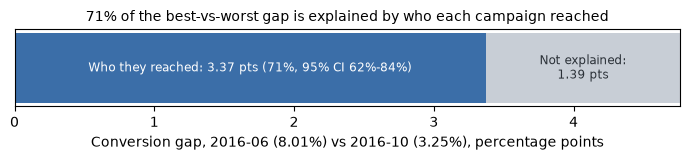

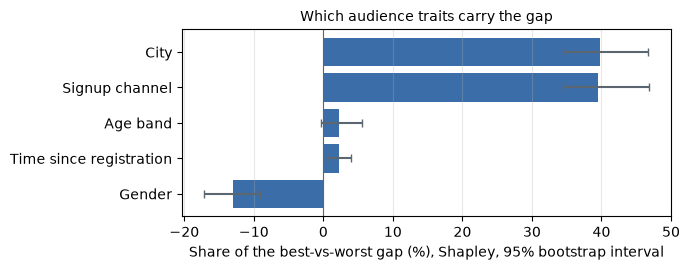

In [7]:
table = pd.read_parquet(CACHE / 'campaign_rates.parquet')
campaign_rates.draw_campaign_chart(table, FIG / 'chart1_raw_vs_adjusted.png')

# Gap bar: the raw best-vs-worst gap split into audience vs everything else.
fig, ax = plt.subplots(figsize=(7, 1.7))
ax.barh([0], [v_all * 100], color='#3b6ea8', height=0.6)
ax.barh([0], [(GAP - v_all) * 100], left=[v_all * 100], color='#c8ced6', height=0.6)
lo_z, hi_z = ci.loc[0.025, 'Z'], ci.loc[0.975, 'Z']
ax.text(v_all * 50, 0, f'Who they reached: {v_all * 100:.2f} pts ({Z:.0%}, 95% CI {lo_z:.0%}-{hi_z:.0%})',
        ha='center', va='center', color='white', fontsize=8.5)
ax.text((v_all + (GAP - v_all) / 2) * 100, 0, f'Not explained:\n{(GAP - v_all) * 100:.2f} pts',
        ha='center', va='center', color='#2b3138', fontsize=8.5)
ax.set_yticks([])
ax.set_xlim(0, GAP * 100)
ax.set_xlabel(f'Conversion gap, {BEST} ({raw.loc[BEST, "rate"]:.2%}) vs {WORST} '
              f'({raw.loc[WORST, "rate"]:.2%}), percentage points')
ax.set_title(f'{Z:.0%} of the best-vs-worst gap is explained by who each campaign reached', fontsize=10)
fig.tight_layout()
fig.savefig(FIG / 'chart2_gap_split.png', dpi=150)
plt.show()

# Per-trait shares with bootstrap intervals.
share = pd.Series({c: p / GAP * 100 for c, p in phi.items()}).sort_values()
lo = ci.loc[0.025, share.index] * 100
hi = ci.loc[0.975, share.index] * 100
labels = {'registered_via': 'Signup channel', 'city': 'City', 'age_band': 'Age band',
          'gender': 'Gender', 'reg_lag_band': 'Time since registration'}
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh([labels[c] for c in share.index], share, color='#3b6ea8',
        xerr=[share - lo, hi - share], ecolor='#5b6670', capsize=3)
ax.axvline(0, color='#5b6670', lw=0.8)
ax.set_xlabel('Share of the best-vs-worst gap (%), Shapley, 95% bootstrap interval')
ax.set_title('Which audience traits carry the gap', fontsize=10)
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / 'chart3_trait_shares.png', dpi=150)
plt.show()

## 7. Summary (numbers quoted in the memo)

In [8]:
summary = {
    'full_trials': len(df), 'modeled_trials': len(data), 'campaigns': modeled,
    'best': BEST, 'worst': WORST,
    'best_rate': raw.loc[BEST, 'rate'], 'worst_rate': raw.loc[WORST, 'rate'], 'gap': GAP,
    'explained': v_all, 'Z': Z, 'Z_ci': [ci.loc[0.025, 'Z'], ci.loc[0.975, 'Z']],
    'trait_share': {c: p / GAP for c, p in phi.items()},
    'trait_share_ci': {c: [ci.loc[0.025, c], ci.loc[0.975, c]] for c in TRAITS},
    'Z_mc_sd': float(np.std(draws)), 'Z_no_profile': Z_np,
    'trait_share_no_profile': {c: p / GAP for c, p in phi_np.items()},
    'Z_reverse': Z_rev, 'pseudo_r2': res.prsquared, 'bootstrap_replicates': len(boot),
    'compositions': {c: t.reset_index().to_dict('records') for c, t in compositions.items()},
}
(ROOT / 'notebooks' / 'who_explains_the_gap_results.json').write_text(json.dumps(summary, indent=2, default=float))
{k: v for k, v in summary.items() if k != 'compositions'}

{'full_trials': 329370,
 'modeled_trials': 321506,
 'campaigns': ['2015-06',
  '2016-06',
  '2016-07',
  '2016-08',
  '2016-09',
  '2016-10',
  '2016-11'],
 'best': '2016-06',
 'worst': '2016-10',
 'best_rate': np.float64(0.08009489380930863),
 'worst_rate': np.float64(0.03247930066451086),
 'gap': np.float64(0.047615593144797776),
 'explained': np.float64(0.033728869172146854),
 'Z': np.float64(0.7083576396828292),
 'Z_ci': [np.float64(0.6200376396732235), np.float64(0.8378185737246858)],
 'trait_share': {'registered_via': np.float64(0.39451714057435855),
  'city': np.float64(0.3981563692593044),
  'age_band': np.float64(0.023143981963361093),
  'gender': np.float64(-0.12941080855061557),
  'reg_lag_band': np.float64(0.02195095643642066)},
 'trait_share_ci': {'registered_via': [np.float64(0.34399491790723924),
   np.float64(0.4681327361198971)],
  'city': [np.float64(0.344726243675847), np.float64(0.4672715603848851)],
  'age_band': [np.float64(-0.003962694654753508),
   np.float64(0.